# Titanic Survival Prediction

## Project Overview

This project uses the Titanic dataset to build a machine learning model that predicts whether a passenger survived the Titanic disaster.

The project follows a complete machine learning workflow:

- Data exploration and exploratory data analysis (EDA)
- Missing-value analysis
- Feature engineering
- Data preprocessing
- Classification model training
- 5-fold cross-validation
- Model evaluation
- Hyperparameter tuning with GridSearchCV
- Final prediction on the test dataset
- Creation of a submission file

### Objective

The objective is to predict passenger survival using demographic, family, fare, class, and cabin-related features.

## 1. Import Libraries

In [522]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load and Understand the Dataset

In [523]:
import pandas as pd
train=pd.read_csv("train.csv")
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [524]:
train.shape


(891, 12)

In [525]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [526]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [527]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [528]:
train["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

### Dataset Overview

The training dataset contains 891 passenger records and 12 columns, including passenger information, demographic characteristics, ticket information, and the target variable `Survived`.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Distribution

In [529]:
percentages = train["Survived"].value_counts(normalize=True) * 100

print("Survival Percentages:")
print(percentages)

Survival Percentages:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


The target variable is moderately imbalanced, with 61.62% of passengers not surviving and 38.38% surviving. Although the classes are not severely imbalanced, this distribution should be considered when evaluating the classification models.

### 3.2 Survival by Sex

In [530]:
# Group by Sex and calculate the mean of Survived (which equals the survival rate)
survival_rate_by_sex = train.groupby('Sex')['Survived'].mean() * 100

print("Survival Rate by Sex (%):")
print(survival_rate_by_sex)

Survival Rate by Sex (%):
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


Female passengers had a substantially higher survival rate than male passengers. Approximately 74.20% of female passengers survived, compared with only 18.89% of male passengers. This indicates that Sex is an important predictive feature for the survival model.

### 3.3 Survival by Passenger Class

In [531]:
survival_rate_by_Pclass = train.groupby('Pclass')['Survived'].mean() * 100

print("Survival Rate by Pclass (%):")
print(survival_rate_by_Pclass)

Survival Rate by Pclass (%):
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


Passengers in higher classes had higher survival rates. First-class passengers had a survival rate of 62.96%, compared with 47.28% for second class and 24.24% for third class. This suggests that passenger class is strongly associated with survival.

### 3.4 Survival by Sex and Passenger Class

In [532]:
survival_rate = train.groupby(["Sex", "Pclass"])["Survived"].mean() * 100

print(survival_rate)

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64


The combination of Sex and Passenger Class reveals an even stronger relationship with survival. Female passengers had much higher survival rates than male passengers across all classes, while first-class passengers generally had better outcomes than those in lower classes. This interaction suggests that using both features together can provide more useful information than considering either feature alone.

In [533]:
# Count the number of passengers in each group
passenger_counts = train.groupby(["Sex", "Pclass"]).size()

print("Passenger Counts by Sex and Pclass:")
print(passenger_counts)

Passenger Counts by Sex and Pclass:
Sex     Pclass
female  1          94
        2          76
        3         144
male    1         122
        2         108
        3         347
dtype: int64


### 3.5 Age Analysis

In [534]:
# 1. Number of known ages (ignores missing/NaN values)
known_ages = train["Age"].count()
print(f"Number of known ages: {known_ages}")

# 2. Minimum age
min_age=train["Age"].min()
print(f"Minimum Age:{min_age}")


# 3. Maximum age
max_age=train["Age"].max()
print(f"Maximum Age:{max_age}")

# 4. Mean (average) age
mean_age = train["Age"].mean()
print(f"Mean age: {mean_age}")

# 5. Median age (the exact middle value)
median_age = train["Age"].median()
print(f"Median age: {median_age}")

Number of known ages: 714
Minimum Age:0.42
Maximum Age:80.0
Mean age: 29.69911764705882
Median age: 28.0


There are 714 known age values in the dataset. The average passenger age is approximately 29.7 years, while the median age is 28 years. Since some ages are missing, the Age feature will require imputation during preprocessing.

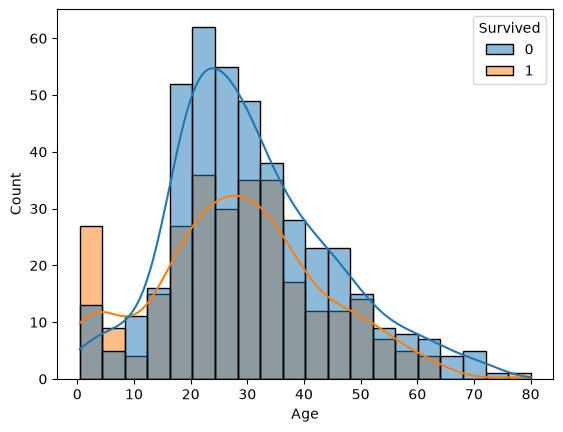

In [535]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=train, x="Age", hue="Survived", kde=True)
plt.show()

The age distribution shows that most passengers were young adults, although passengers from a wide range of ages were present. The distribution also suggests differences in survival across age groups.

In [536]:
import pandas as pd

# 1. Define the edges of the intervals (the buckets)
# This means: 0-12, 12-18, 18-35, 35-60, 60-100
bins = [0, 12, 18, 35, 60, 100]

# 2. Define the names for each bucket
labels = ['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']

# 3. Create the new 'AgeGroup' column using pd.cut()
train['AgeGroup'] = pd.cut(train['Age'], bins=bins, labels=labels)

# 4. Calculate the survival rate for each AgeGroup
survival_rate = train.groupby('AgeGroup')['Survived'].mean() * 100

print("Survival Rate by Age Group (%):")
print(survival_rate)

Survival Rate by Age Group (%):
AgeGroup
Child          57.971014
Teen           42.857143
Young Adult    38.268156
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


In [537]:
# Count the number of passengers in each AgeGroup
age_group_counts = train['AgeGroup'].value_counts()

print("Passenger Counts by Age Group:")
print(age_group_counts)

Passenger Counts by Age Group:
AgeGroup
Young Adult    358
Adult          195
Teen            70
Child           69
Senior          22
Name: count, dtype: int64


Survival rates vary across age groups. Children had a relatively high survival rate, while senior passengers had a lower survival rate. These differences suggest that Age may contribute useful information to the prediction model.

In [538]:
print("Survival Rate by SibSp (%):")
print(train.groupby('SibSp')['Survived'].mean() * 100)

print("\nSurvival Rate by Parch (%):")
print(train.groupby('Parch')['Survived'].mean() * 100)

Survival Rate by SibSp (%):
SibSp
0    34.539474
1    53.588517
2    46.428571
3    25.000000
4    16.666667
5     0.000000
8     0.000000
Name: Survived, dtype: float64

Survival Rate by Parch (%):
Parch
0    34.365782
1    55.084746
2    50.000000
3    60.000000
4     0.000000
5    20.000000
6     0.000000
Name: Survived, dtype: float64


### 3.6 Family Size Analysis

In [539]:
# Create a new column called 'FamilySize'
# We add SibSp + Parch + 1 (the 1 represents the passenger themselves)
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

# Now let's see the survival rate based on total family size!
print("\nSurvival Rate by Family Size (%):")
print(train.groupby('FamilySize')['Survived'].mean() * 100)


Survival Rate by Family Size (%):
FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


Family size appears to have a non-linear relationship with survival. Passengers traveling with small families generally had higher survival rates than passengers traveling alone or in very large families. This motivates creating the `FamilySize` feature, calculated as `SibSp + Parch + 1`.

### 3.7 Fare Analysis

In [540]:
import pandas as pd

# 1. Minimum fare
min_fare = train["Fare"].min()
print(f"Minimum fare: ${min_fare:.2f}")

# 2. Maximum fare
max_fare = train["Fare"].max()
print(f"Maximum fare: ${max_fare:.2f}")

# 3. Mean (average) fare
mean_fare = train["Fare"].mean()
print(f"Mean fare: ${mean_fare:.2f}")

# 4. Median fare (the exact middle value)
median_fare = train["Fare"].median()
print(f"Median fare: ${median_fare:.2f}")

Minimum fare: $0.00
Maximum fare: $512.33
Mean fare: $32.20
Median fare: $14.45


Passenger fares vary substantially, ranging from $0 to approximately $512.33. The mean fare is $32.20, while the median is $14.45, indicating a right-skewed distribution with some passengers paying considerably higher fares.

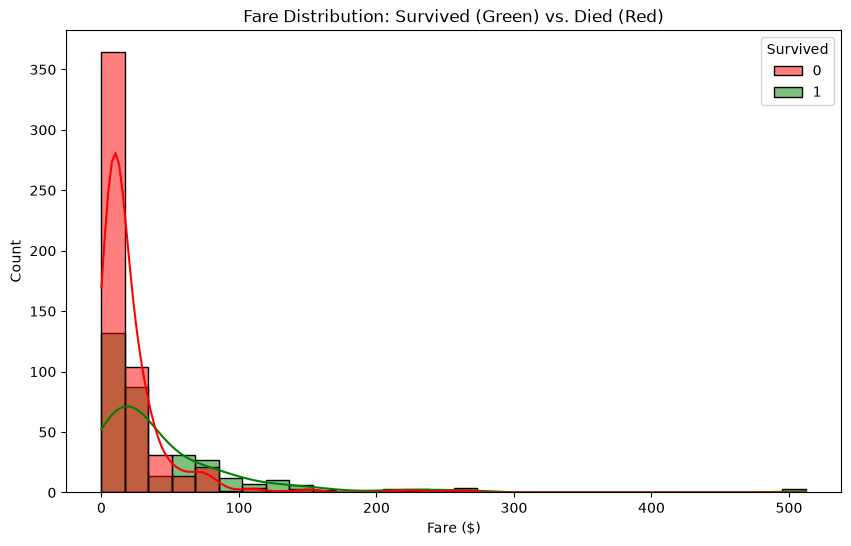

In [541]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create the histogram, splitting by Survived
sns.histplot(
    data=train, 
    x="Fare", 
    hue="Survived", 
    kde=True, 
    bins=30,
    palette={0: 'red', 1: 'green'}
)

plt.title("Fare Distribution: Survived (Green) vs. Died (Red)")
plt.xlabel("Fare ($)")
plt.ylabel("Count")
plt.show()

The fare distribution is strongly right-skewed, with most passengers paying relatively low fares and a smaller number paying much higher fares. Fare may provide additional information about passenger class and socioeconomic status.

### 3.8 Survival by Port of Embarkation

In [542]:
# Group by Embarked and calculate the mean of Survived
survival_rate_embarked = train.groupby("Embarked")["Survived"].mean() * 100

print("Survival Rate by Embarked (%):")
print(survival_rate_embarked)

Survival Rate by Embarked (%):
Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64


Survival rates differ across the three embarkation ports. Passengers who embarked at Cherbourg (C) had the highest survival rate, while passengers who embarked at Southampton (S) had the lowest. The difference may partly reflect the passenger demographics and class distribution at each port.

### 3.9 Survival by Cabin Availability

In [543]:
import pandas as pd

# 1. Create a new column called 'Cabin_Status'
# notna() checks if the cabin is recorded. We map True/False to your exact labels!
train['Cabin_Status'] = train['Cabin'].notna().map({
    True: 'Cabin recorded', 
    False: 'Cabin missing'
})

# 2. Calculate the survival rate for these two groups
survival_rate_cabin = train.groupby('Cabin_Status')['Survived'].mean() * 100

print("Survival Rate by Cabin Status (%):")
print(survival_rate_cabin)

Survival Rate by Cabin Status (%):
Cabin_Status
Cabin missing     29.985444
Cabin recorded    66.666667
Name: Survived, dtype: float64


Passengers with a recorded cabin had a substantially higher survival rate than passengers whose cabin information was missing. Because the Cabin column contains many missing values, instead of using the raw cabin number, we create the `Cabin_Status` feature to indicate whether cabin information is available.

### 3.10 Passenger Title Analysis

In [544]:
# 1. Split the string at ", " (comma + space) and take the right side (index 1)
#    "Braund, Mr. Owen Harris" -> ["Braund", "Mr. Owen Harris"] -> "Mr. Owen Harris"
first_split = train['Name'].str.split(', ', expand=True)[1]

# 2. Split that result at "." and take the left side (index 0)
#    "Mr. Owen Harris" -> ["Mr", " Owen Harris"] -> "Mr"
train['Title'] = first_split.str.split('.', expand=True)[0]

# Check our new column
print(train[['Name', 'Title']].head())

                                                Name Title
0                            Braund, Mr. Owen Harris    Mr
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs
2                             Heikkinen, Miss. Laina  Miss
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs
4                           Allen, Mr. William Henry    Mr


Passenger titles show substantial differences in survival rates. Female titles such as Mrs and Miss have higher survival rates, while Mr has a much lower survival rate. Because many titles occur only a few times, uncommon titles are grouped into a single `Rare` category to reduce the number of categories used by the model.

In [545]:
train["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [546]:
print("Survival Rate by Title (%):")
print(train.groupby('Title')['Survived'].mean() * 100)

Survival Rate by Title (%):
Title
Capt              0.000000
Col              50.000000
Don               0.000000
Dr               42.857143
Jonkheer          0.000000
Lady            100.000000
Major            50.000000
Master           57.500000
Miss             69.780220
Mlle            100.000000
Mme             100.000000
Mr               15.667311
Mrs              79.200000
Ms              100.000000
Rev               0.000000
Sir             100.000000
the Countess    100.000000
Name: Survived, dtype: float64


In [547]:
# List of titles we want to keep
main_titles = ['Mr', 'Miss', 'Mrs', 'Master']

# Replace anything not in the main list with 'Rare'
train['Title'] = train['Title'].apply(lambda x: x if x in main_titles else 'Rare')

# Verify the counts
print(train['Title'].value_counts())

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64


In [548]:
# Group by the new 'Title' column and calculate the mean of Survived
survival_rate_by_title = train.groupby('Title')['Survived'].mean() * 100

print("Survival Rate by Title (%):")
print(survival_rate_by_title)

Survival Rate by Title (%):
Title
Master    57.500000
Miss      69.780220
Mr        15.667311
Mrs       79.200000
Rare      44.444444
Name: Survived, dtype: float64


### 3.11 Survival by Deck

In [549]:
import pandas as pd
import numpy as np

# 1. Extract the first letter using .str[0]
train['Deck'] = train['Cabin'].str[0]

# 2. Let's look at a few rows where Cabin is NOT missing to see if it worked
print(train[['Cabin', 'Deck']].dropna().head(10))

          Cabin Deck
1           C85    C
3          C123    C
6           E46    E
10           G6    G
11         C103    C
21          D56    D
23           A6    A
27  C23 C25 C27    C
31          B78    B
52          D33    D


In [550]:
# Calculate the survival rate for each Deck
survival_by_deck = train.groupby('Deck')['Survived'].mean() * 100

print("Survival Rate by Deck (%):")
print(survival_by_deck)

Survival Rate by Deck (%):
Deck
A    46.666667
B    74.468085
C    59.322034
D    75.757576
E    75.000000
F    61.538462
G    50.000000
T     0.000000
Name: Survived, dtype: float64


The first letter of the cabin number was extracted as the `Deck` feature. Survival rates vary across decks, suggesting that cabin location may contain useful information about a passenger's location on the ship and their likelihood of survival.

### 3.12 Key EDA Insights

The exploratory analysis revealed several important patterns:

- **Sex:** Female passengers had a much higher survival rate than male passengers.
- **Passenger Class:** First-class passengers had higher survival rates than second- and third-class passengers.
- **Age:** Survival varied across age groups, with children showing relatively higher survival rates than senior passengers.
- **Family Size:** Passengers traveling with small families generally had better survival outcomes than passengers traveling alone or in very large families.
- **Fare:** Fare was strongly right-skewed and may provide information related to passenger class and socioeconomic status.
- **Embarkation:** Survival rates differed across the three embarkation ports.
- **Cabin Information:** Passengers with recorded cabin information had a higher survival rate than those with missing cabin information.
- **Title:** Passenger titles showed strong differences in survival, making `Title` a useful engineered feature.
- **Deck:** Cabin deck also showed differences in survival rates and was therefore retained as a feature.

These findings guided the feature engineering and preprocessing decisions used in the machine learning models.

## 4. Data Preprocessing and Feature Engineering

The exploratory analysis identified several features that are useful for predicting passenger survival. Before training the models, the data must be prepared by selecting the relevant features, handling missing values, encoding categorical variables, and scaling numerical features.

A preprocessing pipeline is used to ensure that the same transformations are applied consistently to the training and validation data while avoiding data leakage.

### 4.1 Select Features and Target

In [551]:
# 1. Define the features (columns we will use to predict)
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title",
    "Deck",
    "Cabin_Status"
]

# 2. Define the target (what we are trying to predict)
target = "Survived"

# 3. Create X (the features) and y (the target)
X = train[features]
y = train[target]

# Optional: Check the shapes to make sure it worked
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (891, 11)
y shape: (891,)


The model uses 11 features selected from the original dataset and the engineered features created during EDA. The target variable is `Survived`, which indicates whether the passenger survived.

The raw `Name`, `Ticket`, `Cabin`, and `PassengerId` columns are not used directly. Instead, useful information was extracted from `Name` and `Cabin` through the engineered `Title`, `Deck`, and `Cabin_Status` features.

### 4.2 Train-Validation Split

In [552]:
from sklearn.model_selection import train_test_split

# Split the data: 80% for training the model, 20% for validating it
X_train, X_val, y_train, y_val = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y # This ensures the 38% survival rate is kept perfectly balanced in both sets
)

print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train shape: (712, 11)
X_val shape: (179, 11)
y_train: (712,)
y_val: (179,)


The dataset was split into 80% training data and 20% validation data. Stratification was used to preserve the proportion of survivors and non-survivors in both sets.

The validation set is kept separate from model training so that the trained models can be evaluated on unseen data.

In [553]:
print("Training missing values:")
print(X_train.isnull().sum())

print("\nValidation missing values:")
print(X_val.isnull().sum())

Training missing values:
Pclass            0
Sex               0
Age             137
SibSp             0
Parch             0
Fare              0
Embarked          2
FamilySize        0
Title             0
Deck            552
Cabin_Status      0
dtype: int64

Validation missing values:
Pclass            0
Sex               0
Age              40
SibSp             0
Parch             0
Fare              0
Embarked          0
FamilySize        0
Title             0
Deck            135
Cabin_Status      0
dtype: int64


### 4.3 Build Preprocessing Pipelines

In [554]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Numerical features
numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "FamilySize"
]

# Categorical features
categorical_features = [
    "Sex",
    "Embarked",
    "Title",
    "Deck",
    "Cabin_Status"
]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

The preprocessing workflow treats numerical and categorical features differently.

Numerical features are completed using median imputation and then standardized using `StandardScaler`. Categorical features are completed using the most frequent category and then converted into numerical values using one-hot encoding.

The preprocessing is kept inside a `ColumnTransformer` so that the correct transformation is automatically applied to each feature type.

## 5. Model Training and Cross-Validation

Three machine learning algorithms are evaluated: Logistic Regression, Random Forest, and XGBoost. Each model uses the same preprocessing pipeline so that their performance can be compared fairly.

# 5.1 Define the Models

In [555]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        random_state=42,
        
    ))
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

# 5.2 Model Comparison

The cross-validation results are summarized below to compare the average accuracy and consistency of the three models.

In [556]:
# Put all your pipelines into a dictionary
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

print("--- Model Comparison (5-Fold Cross Validation) ---")

cv_results = {}

for name, pipeline in models.items():
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_results[name] = {
        "mean": scores.mean(),
        "std": scores.std()
    }

    print(
        f"{name:20} | "
        f"Avg Accuracy: {scores.mean():.2%} | "
        f"Std Dev: {scores.std():.2%}"
    )

--- Model Comparison (5-Fold Cross Validation) ---
Logistic Regression  | Avg Accuracy: 82.03% | Std Dev: 2.84%

c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Random Forest        | Avg Accuracy: 79.93% | Std Dev: 3.87%


c:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


XGBoost              | Avg Accuracy: 78.66% | Std Dev: 3.45%


Logistic Regression achieved the highest average cross-validation accuracy among the three models. Random Forest achieved a lower average accuracy, while XGBoost had the lowest average cross-validation accuracy in this comparison.

The standard deviation shows how much the model's performance varied across the five validation folds. These cross-validation results provide a basis for comparing the models before evaluating them on the separate validation set.

#5.3 Train Models on Training Data

In [557]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric="logloss"
    ))
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

In [558]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)

# 5.4 Train Models on Training Data

In [559]:
# Train all models on the training data
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f" {name} trained successfully.")

 Logistic Regression trained successfully.
 Random Forest trained successfully.
 XGBoost trained successfully.


In [560]:
predictions = {}

# Make predictions on the validation set
for name, pipeline in models.items():
    predictions[name] = pipeline.predict(X_val)
    print(f" {name}: predictions generated successfully.")

 Logistic Regression: predictions generated successfully.
 Random Forest: predictions generated successfully.
 XGBoost: predictions generated successfully.


## 6. Model Evaluation

# 6.1 Accuracy, Precision, and Recall

In [561]:
evaluation_results = []

for name, pipeline in models.items():
    y_pred = predictions[name]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred)
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.821229,0.803279,0.710145
1,Random Forest,0.787709,0.738462,0.695652
2,XGBoost,0.826816,0.771429,0.782609


# 6.2 Confusion Matrices

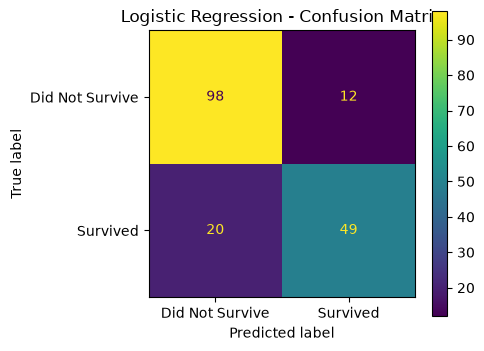

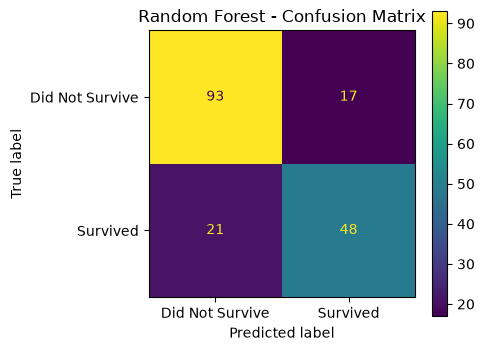

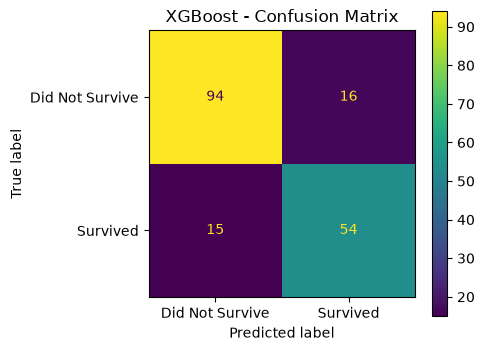

In [562]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        display_labels=["Did Not Survive", "Survived"],
        ax=ax
    )

    ax.set_title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

### 7 Hyperparameter Tuning

# 7.1 Define Parameter Grid

In [563]:
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# 7.2 GridSearchCV

In [564]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [565]:
grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Best parameters: {'classifier__C': 10}
Best CV accuracy: 0.823116320299419


# 7.3 Evaluate Tuned Model

In [566]:
best_model = grid_search.best_estimator_
y_val_pred_tuned = best_model.predict(X_val)
print(f"Tuned Validation Accuracy: {accuracy_score(y_val, y_val_pred_tuned):.2%}")

Tuned Validation Accuracy: 83.80%


# 8. Final Model

# 8.1 Train Final Model on Full Dataset

In [567]:
final_model = grid_search.best_estimator_
final_model.fit(X, y) # We use X and y (the full training data) here!

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Pclass','Sex','Age',...,'Title','Deck','Cabin_Status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [568]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

print("Tuned Logistic Regression")
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred_tuned):.2%}")
print(f"Precision: {precision_score(y_val, y_val_pred_tuned):.2%}")
print(f"Recall:    {recall_score(y_val, y_val_pred_tuned):.2%}")

Tuned Logistic Regression
Accuracy:  83.80%
Precision: 81.25%
Recall:    75.36%


# 9. Test Prediction and Submission

## 9.1 Load Test Dataset

In [569]:
test = pd.read_csv("test.csv")
test.head()


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 9.2 Feature Engineering on Test Set

In [570]:
test_processed = test.copy()

In [571]:
test_processed["FamilySize"] = (
    test_processed["SibSp"] +
    test_processed["Parch"] +
    1
)

In [572]:
test_processed["Title"] = (
    test_processed["Name"]
    .str.extract(r",\s*([^.]*)\.", expand=False)
    .str.strip()
)

In [573]:
title_mapping = {
    "Mlle": "Miss",
    "Ms": "Miss",
    "Mme": "Mrs"
}

test_processed["Title"] = test_processed["Title"].replace(title_mapping)

common_titles = ["Mr", "Miss", "Mrs", "Master"]

test_processed["Title"] = test_processed["Title"].where(
    test_processed["Title"].isin(common_titles),
    "Rare"
)

In [574]:
test_processed["Cabin_Status"] = test_processed["Cabin"].notna().map({
    True: "Cabin recorded",
    False: "Cabin missing"
})

In [575]:
test_processed["Deck"] = test_processed["Cabin"].str[0]

In [576]:
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked",
    "FamilySize",
    "Title",
    "Deck",
    "Cabin_Status"
]

X_test = test_processed[features]

In [577]:
X_test.shape

(418, 11)

In [578]:
X_test.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,Title,Deck,Cabin_Status
0,3,male,34.5,0,0,7.8292,Q,1,Mr,NaN,Cabin missing
1,3,female,47.0,1,0,7.0000,S,2,Mrs,NaN,Cabin missing
2,2,male,62.0,0,0,9.6875,Q,1,Mr,NaN,Cabin missing
3,3,male,27.0,0,0,8.6625,S,1,Mr,NaN,Cabin missing
4,3,female,22.0,1,1,12.2875,S,3,Mrs,NaN,Cabin missing


In [579]:
print(X_test.shape)
X_test.head()

(418, 11)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,Title,Deck,Cabin_Status
0,3,male,34.5,0,0,7.8292,Q,1,Mr,NaN,Cabin missing
1,3,female,47.0,1,0,7.0000,S,2,Mrs,NaN,Cabin missing
2,2,male,62.0,0,0,9.6875,Q,1,Mr,NaN,Cabin missing
3,3,male,27.0,0,0,8.6625,S,1,Mr,NaN,Cabin missing
4,3,female,22.0,1,1,12.2875,S,3,Mrs,NaN,Cabin missing


In [580]:
final_model = grid_search.best_estimator_
final_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Pclass','Sex','Age',...,'Title','Deck','Cabin_Status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

 9.3 Generate Predictions

In [581]:
test_predictions = final_model.predict(X_test)
print("Number of predictions:", len(test_predictions))
print("Unique predictions:", set(test_predictions))

Number of predictions: 418
Unique predictions: {np.int64(0), np.int64(1)}


In [582]:
final_model = grid_search.best_estimator_
final_model.fit(X, y)
test_predictions = final_model.predict(X_test)
print(test_predictions.shape)
print(test_predictions[:20])

print(pd.Series(test_predictions).value_counts())

print("Number of predictions:", len(test_predictions))
print("Unique predictions:", set(test_predictions))

(418,)
[0 1 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1]
0    248
1    170
Name: count, dtype: int64
Number of predictions: 418
Unique predictions: {np.int64(0), np.int64(1)}


## 9.4 Create Submission File

In [583]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

In [584]:
submission.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [585]:
submission.shape

(418, 2)

In [586]:
submission.isnull().sum()

PassengerId    0
Survived       0
dtype: int64

In [587]:
submission.to_csv("titanic_submission.csv", index=False)

In [588]:
submission_check = pd.read_csv("titanic_submission.csv")

print(submission_check.shape)
print(submission_check.head())
print(submission_check.columns.tolist())

(418, 2)
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
['PassengerId', 'Survived']


In [589]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

print(submission.shape)
print(submission.head())
print(submission.isnull().sum())

(418, 2)
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
PassengerId    0
Survived       0
dtype: int64


In [590]:
submission.to_csv("titanic_submission.csv", index=False)

In [591]:
import os

print(os.path.exists("titanic_submission.csv"))

True


In [592]:
submission_check = pd.read_csv("titanic_submission.csv")

print(submission_check.shape)
print(submission_check.columns.tolist())
print(submission_check.head())

(418, 2)
['PassengerId', 'Survived']
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


In [593]:
submission.to_csv("titanic_submission.csv", index=False)

In [594]:
submission_check = pd.read_csv("titanic_submission.csv")

print(submission_check.shape)
print(submission_check.columns.tolist())
print(submission_check.head())

(418, 2)
['PassengerId', 'Survived']
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


# 10. Final Insights and Conclusion

## Key Findings

The exploratory data analysis showed several important patterns in
Titanic passenger survival:

- Female passengers had a substantially higher survival rate than male
  passengers.
- Passengers in higher classes generally had higher survival rates.
- Family size was associated with survival, with some medium-sized
  families showing higher survival rates.
- Passengers with recorded cabin information had a different survival
  pattern from passengers without cabin information.
- Age, passenger class, sex, and engineered features such as Title,
  Deck, and FamilySize provided useful information for prediction.

## Model Performance

Three classification models were evaluated:

- Logistic Regression
- Random Forest
- XGBoost

Logistic Regression provided consistent cross-validation performance.
GridSearchCV was then used to tune its regularization parameter.

The best parameter was C = 10.

The tuned Logistic Regression model achieved approximately:

- Accuracy: 83.80%
- Precision: 81.25%
- Recall: 75.36%

## Final Model

After selecting and tuning the model, the final Logistic Regression
pipeline was trained using the complete training dataset.

The final model was then used to generate predictions for the Kaggle
test dataset.

## Conclusion

This project demonstrated a complete machine learning workflow,
including exploratory data analysis, feature engineering, preprocessing,
cross-validation, model comparison, hyperparameter tuning, and final
prediction generation.

The final predictions were saved in the required submission format
with PassengerId and Survived columns.